<a href="https://colab.research.google.com/github/miriamamin1213-ux/ValidationSET/blob/main/HancockANN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Using device: cpu
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Rows: 332 | Train: 215 | Validation: 50 | Test: 67
Class counts (train): {0: 123, 1: 92}
Class counts (validation): {0: 29, 1: 21}
Class counts (test): {0: 39, 1: 28}
Original predictor count: 6
Encoded feature count: 19
Automatic class weights: [0.87398374 1.16847826]
SMOTE: False
Epoch 001/500 | train loss=0.6981 | val loss=0.6982 | val ROC-AUC=0.4967 | val PR-AUC=0.4951 | val balanced accuracy=0.5164
Epoch 025/500 | train loss=0.4782 | val loss=0.5758 | val ROC-AUC=0.7677 | val PR-AUC=0.7663 | val balanced accuracy=0.7365
Epoch 050/500 | train loss=0.4255 | val loss=0.6094 | val ROC-AUC=0.7644 | val PR-AUC=0.7609 | val balanced accuracy=0.7258
Epoch 075/500 | train loss=0.3931 | val loss=0.6205 | val ROC-AUC=0.7677 | val PR-AUC=0.7361 | val balanced accuracy=0.7323
Epoch 100/500 | train loss=0.3793 | val loss=0.6737 | val ROC-AUC=0.7545 |

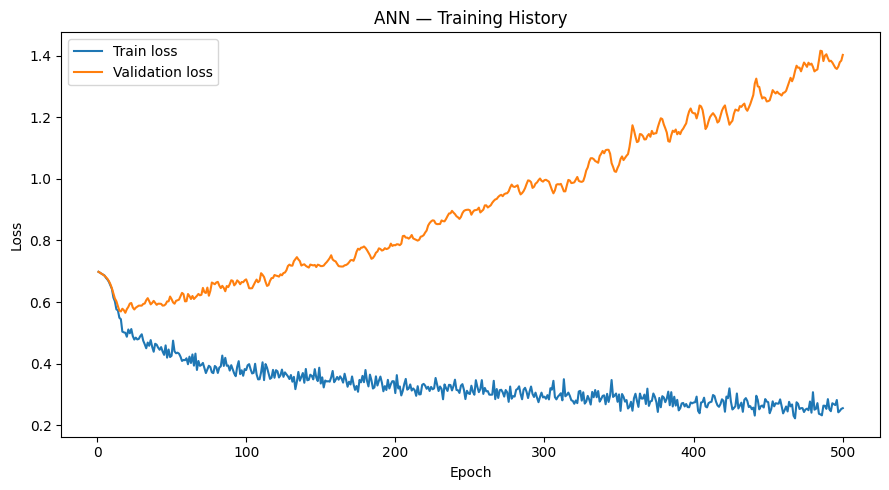


CHECKPOINT: best_val_loss
Epoch: 19
Validation-selected threshold: 0.440

TEST METRICS
Checkpoint                      best_val_loss
Checkpoint_Epoch                           19
Validation_Loss                      0.565085
Validation_ROC_AUC                   0.775862
Validation_PR_AUC                    0.770224
Validation_Balanced_Accuracy         0.729885
Threshold                                0.44
Accuracy                             0.731343
Balanced_Accuracy                    0.728938
Precision                            0.666667
Recall                               0.714286
F1                                   0.689655
ROC_AUC                              0.800366
PR_AUC                               0.788047

Confusion matrix:
[[29 10]
 [ 8 20]]

Classification report:
              precision    recall  f1-score   support

           0       0.78      0.74      0.76        39
           1       0.67      0.71      0.69        28

    accuracy                           0.7

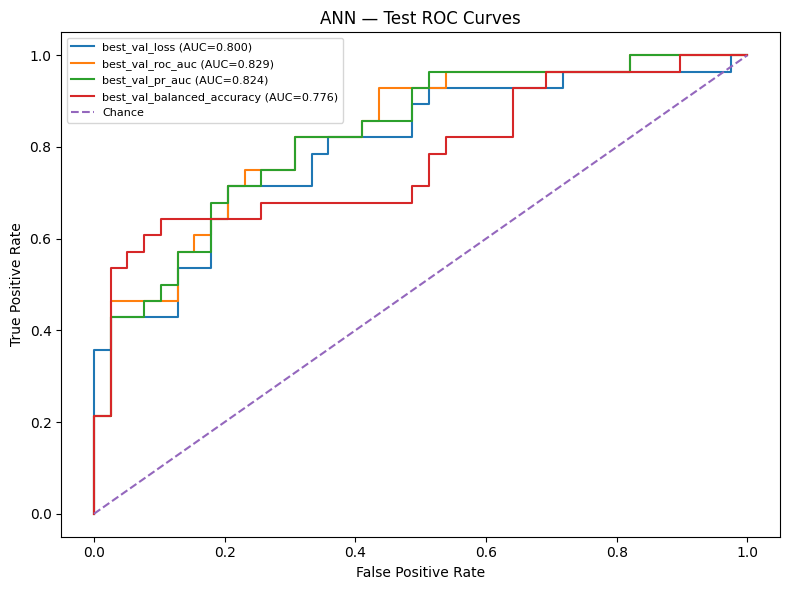

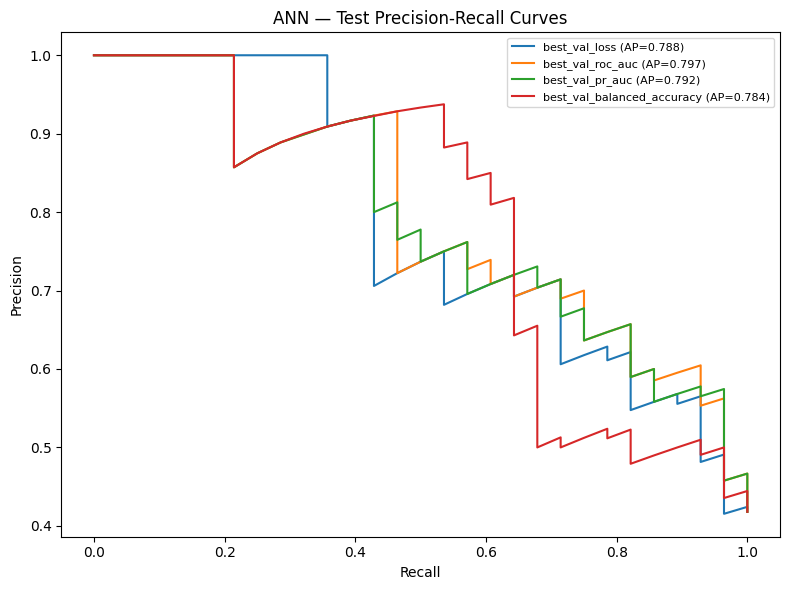


ANN CHECKPOINT COMPARISON — TEST SET
                Checkpoint  Checkpoint_Epoch  Threshold  Accuracy  Balanced_Accuracy  Precision   Recall       F1  ROC_AUC   PR_AUC
             best_val_loss                19      0.440  0.731343           0.728938   0.666667 0.714286 0.689655 0.800366 0.788047
          best_val_roc_auc                46      0.330  0.761194           0.754579   0.714286 0.714286 0.714286 0.828755 0.796768
           best_val_pr_auc                43      0.315  0.746269           0.746795   0.677419 0.750000 0.711864 0.824176 0.791646
best_val_balanced_accuracy               201      0.285  0.701493           0.693223   0.642857 0.642857 0.642857 0.775641 0.783767

Saved all results to: /content/drive/MyDrive/ANN_results
Saved checkpoints to: /content/drive/MyDrive/ANN_results/checkpoints

Output files:
 - ANN_epoch_history.csv
 - ANN_results.csv
 - ANN_test_predictions.csv
 - ann_preprocessor.joblib
 - best_ann_model.pt
 - checkpoint_summary.csv
 - checkpoints

In [5]:

# ============================================================
# ANN — HANCOCK HPV CLASSIFIER
# GPT-2-aligned data preparation | Seed 42 | No SMOTE
# Full 500 epochs | Four validation-selected checkpoints
# ============================================================

import os
import json
import random
import copy
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

from torch.utils.data import TensorDataset, DataLoader
from google.colab import drive

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve
)

warnings.filterwarnings("ignore", category=FutureWarning)

SEED = 42
MAX_EPOCHS = 500
BATCH_SIZE = 32


def seed_everything(seed=42):
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


seed_everything(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

drive.mount("/content/drive")


# ------------------------------------------------------------
# 1. LOAD AND PREPARE DATA
# ------------------------------------------------------------

BASE = "/content/drive/MyDrive"
OUT_DIR = os.path.join(BASE, "ANN_results")
CHECKPOINT_DIR = os.path.join(OUT_DIR, "checkpoints")

os.makedirs(OUT_DIR, exist_ok=True)
os.makedirs(CHECKPOINT_DIR, exist_ok=True)


def load_json_table(path):
    with open(path, "r", encoding="utf-8") as f:
        obj = json.load(f)

    if isinstance(obj, list):
        return pd.DataFrame(obj)

    if isinstance(obj, dict):
        for key in ["data", "records", "patients", "items"]:
            if key in obj and isinstance(obj[key], list):
                return pd.DataFrame(obj[key])

        return pd.DataFrame(obj)

    raise ValueError(f"Cannot read table from {path}")


clinical = load_json_table(
    os.path.join(BASE, "clinical_data.json")
)

pathology = load_json_table(
    os.path.join(BASE, "pathological_data.json")
)

if "patient_id" not in clinical or "patient_id" not in pathology:
    raise KeyError("Both files must contain patient_id.")

# Same left join as the GPT-2 notebook.
df = clinical.merge(
    pathology,
    on="patient_id",
    how="left",
    suffixes=("", "_path")
)

# Same target priority as the GPT-2 notebook.
target_candidates = [
    "hpv_association_p16",
    "hpv_association_p16_path"
]

target_col = next(
    (c for c in target_candidates if c in df.columns),
    None
)

if target_col is None:
    raise KeyError("HPV target column was not found.")


# Same feature set and fallback approach as the reference notebook.
feature_candidates = {
    "age_at_initial_diagnosis": [
        "age_at_initial_diagnosis"
    ],
    "sex": [
        "sex"
    ],
    "smoking_status": [
        "smoking_status"
    ],
    "primary_tumor_site": [
        "primary_tumor_site"
    ],
    "primarily_metastasis": [
        "primarily_metastasis"
    ],
    "pN_stage": [
        "pN_stage",
        "pN_stage_path",
        "pathological_N_stage",
        "pathological_n_stage"
    ]
}

rename_map = {}

for name, candidates in feature_candidates.items():
    match = next(
        (c for c in candidates if c in df.columns),
        None
    )

    if match is None:
        raise KeyError(
            f"Missing predictor {name}; checked {candidates}"
        )

    if match != name:
        rename_map[match] = name

df = df.rename(columns=rename_map)
features = list(feature_candidates.keys())


# Normalize the binary target using the GPT-2 approach.
def normalize_label(value):
    if pd.isna(value):
        return np.nan

    value = str(value).strip().lower()

    if value in {"negative", "neg", "0", "false", "no"}:
        return 0

    if value in {"positive", "pos", "1", "true", "yes"}:
        return 1

    try:
        number = float(value)

        if number in (0.0, 1.0):
            return int(number)

    except (ValueError, TypeError):
        pass

    return np.nan


df["HPV_Label"] = df[target_col].map(normalize_label)
df = df.dropna(subset=["HPV_Label"]).copy()
df["HPV_Label"] = df["HPV_Label"].astype(int)

df = df[["patient_id"] + features + ["HPV_Label"]].copy()


# ------------------------------------------------------------
# 2. STRATIFIED TRAIN / VALIDATION / TEST SPLIT
# ------------------------------------------------------------

# Same two-stage split and random states as GPT-2.
train_val, test = train_test_split(
    df,
    test_size=0.20,
    random_state=SEED,
    stratify=df["HPV_Label"]
)

train, val = train_test_split(
    train_val,
    test_size=0.1875,
    random_state=SEED,
    stratify=train_val["HPV_Label"]
)

# Reset indices for clean alignment in downstream outputs.
train = train.reset_index(drop=True)
val = val.reset_index(drop=True)
test = test.reset_index(drop=True)

print(
    "Rows:", len(df),
    "| Train:", len(train),
    "| Validation:", len(val),
    "| Test:", len(test)
)

print(
    "Class counts (train):",
    train["HPV_Label"].value_counts().sort_index().to_dict()
)

print(
    "Class counts (validation):",
    val["HPV_Label"].value_counts().sort_index().to_dict()
)

print(
    "Class counts (test):",
    test["HPV_Label"].value_counts().sort_index().to_dict()
)


# ------------------------------------------------------------
# 3. IMPUTATION, SCALING AND ONE-HOT ENCODING
# ------------------------------------------------------------

# Match GPT-2's train-only imputation logic.
# One-hot encoding is required for the ANN's numeric input.

numeric_features = ["age_at_initial_diagnosis"]

categorical_features = [
    c for c in features if c not in numeric_features
]

X_train_df = train[features].copy()
X_val_df = val[features].copy()
X_test_df = test[features].copy()

# Convert age to numeric and impute using the training median only.
for frame in [X_train_df, X_val_df, X_test_df]:
    frame["age_at_initial_diagnosis"] = pd.to_numeric(
        frame["age_at_initial_diagnosis"],
        errors="coerce"
    )

age_median = X_train_df["age_at_initial_diagnosis"].median()

if pd.isna(age_median):
    age_median = 0.0

for frame in [X_train_df, X_val_df, X_test_df]:
    frame["age_at_initial_diagnosis"] = (
        frame["age_at_initial_diagnosis"].fillna(age_median)
    )

# Impute categorical columns using training-set modes only.
for col in categorical_features:
    for frame in [X_train_df, X_val_df, X_test_df]:
        frame[col] = frame[col].astype("object")

        frame[col] = frame[col].replace(
            r"^\s*$",
            np.nan,
            regex=True
        )

        frame[col] = frame[col].replace(
            ["nan", "None", "NaN"],
            np.nan
        )

    mode_values = X_train_df[col].mode(dropna=True)

    fill_value = (
        str(mode_values.iloc[0])
        if not mode_values.empty
        else "Unknown"
    )

    for frame in [X_train_df, X_val_df, X_test_df]:
        frame[col] = frame[col].fillna(fill_value).astype(str)

        frame[col] = frame[col].replace(
            ["", "nan", "None", "NaN"],
            "Unknown"
        )

try:
    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    )
except TypeError:
    # Compatibility with older scikit-learn versions.
    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse=False
    )

preprocessor = ColumnTransformer([
    (
        "num",
        StandardScaler(),
        numeric_features
    ),
    (
        "cat",
        encoder,
        categorical_features
    )
])

# Fit the encoder and scaler on training data only.
X_train = preprocessor.fit_transform(
    X_train_df
).astype(np.float32)

X_val = preprocessor.transform(
    X_val_df
).astype(np.float32)

X_test = preprocessor.transform(
    X_test_df
).astype(np.float32)

y_train = train["HPV_Label"].to_numpy().astype(np.int64)
y_val = val["HPV_Label"].to_numpy().astype(np.int64)
y_test = test["HPV_Label"].to_numpy().astype(np.int64)

print("Original predictor count:", len(features))
print("Encoded feature count:", X_train.shape[1])


# ------------------------------------------------------------
# 4. AUTOMATIC CLASS WEIGHTS — NO SMOTE
# ------------------------------------------------------------

# Inverse-frequency weights calculated from training labels only.
counts = np.bincount(y_train, minlength=2)

if np.any(counts == 0):
    raise ValueError(
        "Both classes must be present in the training set."
    )

weights = len(y_train) / (2.0 * counts)

class_weights = torch.tensor(
    weights,
    dtype=torch.float32,
    device=device
)

print("Automatic class weights:", weights)
print("SMOTE: False")


# ------------------------------------------------------------
# 5. DATA LOADER
# ------------------------------------------------------------

train_dataset = TensorDataset(
    torch.tensor(X_train, dtype=torch.float32),
    torch.tensor(y_train, dtype=torch.long)
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=torch.Generator().manual_seed(SEED)
)

X_val_t = torch.tensor(
    X_val,
    dtype=torch.float32,
    device=device
)

y_val_t = torch.tensor(
    y_val,
    dtype=torch.long,
    device=device
)

X_test_t = torch.tensor(
    X_test,
    dtype=torch.float32,
    device=device
)


# ------------------------------------------------------------
# 6. DEFINE ANN ARCHITECTURE
# ------------------------------------------------------------

class ANNClassifier(nn.Module):
    def __init__(self, input_dim):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.ReLU(),
            nn.Dropout(0.30),

            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Dropout(0.20),

            nn.Linear(32, 16),
            nn.ReLU(),

            nn.Linear(16, 2)
        )

    def forward(self, x):
        return self.network(x)


model = ANNClassifier(X_train.shape[1]).to(device)

# Per-example weighted loss makes the class weighting explicit.
criterion = nn.CrossEntropyLoss(
    weight=class_weights,
    reduction="none"
)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001,
    weight_decay=1e-4
)


# ------------------------------------------------------------
# 7. VALIDATION HELPERS AND CHECKPOINT CRITERIA
# ------------------------------------------------------------

thresholds = np.linspace(0.10, 0.90, 161)


def select_threshold(y_true, probabilities):
    """Maximize validation balanced accuracy; ties closest to 0.5."""
    scores = [
        balanced_accuracy_score(
            y_true,
            (probabilities >= threshold).astype(int)
        )
        for threshold in thresholds
    ]

    max_score = max(scores)

    best_threshold = min(
        (
            threshold
            for threshold, score in zip(thresholds, scores)
            if np.isclose(score, max_score)
        ),
        key=lambda threshold: abs(threshold - 0.5)
    )

    return float(best_threshold), float(max_score)


def predict_probabilities(model, X_tensor):
    model.eval()

    with torch.no_grad():
        probabilities = torch.softmax(
            model(X_tensor),
            dim=1
        )[:, 1].cpu().numpy()

    return probabilities


def calculate_validation_metrics(model):
    probabilities = predict_probabilities(model, X_val_t)

    threshold, bal_acc = select_threshold(
        y_val,
        probabilities
    )

    if len(np.unique(y_val)) == 2:
        roc_auc = roc_auc_score(y_val, probabilities)
    else:
        roc_auc = np.nan

    pr_auc = average_precision_score(
        y_val,
        probabilities
    )

    return {
        "val_probabilities": probabilities,
        "threshold": threshold,
        "balanced_accuracy": bal_acc,
        "roc_auc": float(roc_auc),
        "pr_auc": float(pr_auc)
    }


# Four independent checkpoint-selection rules.
checkpoint_specs = {
    "best_val_loss": {
        "filename": "ann_best_val_loss.pt",
        "direction": "min"
    },
    "best_val_roc_auc": {
        "filename": "ann_best_val_roc_auc.pt",
        "direction": "max"
    },
    "best_val_pr_auc": {
        "filename": "ann_best_val_pr_auc.pt",
        "direction": "max"
    },
    "best_val_balanced_accuracy": {
        "filename": "ann_best_val_balanced_accuracy.pt",
        "direction": "max"
    }
}

best_values = {
    "best_val_loss": float("inf"),
    "best_val_roc_auc": -float("inf"),
    "best_val_pr_auc": -float("inf"),
    "best_val_balanced_accuracy": -float("inf")
}

best_epochs = {}
history = []


# ------------------------------------------------------------
# 8. TRAIN FOR ALL 500 EPOCHS — NO EARLY STOPPING
# ------------------------------------------------------------

for epoch in range(1, MAX_EPOCHS + 1):

    model.train()

    running_loss = 0.0
    seen = 0

    for xb, yb in train_loader:
        xb = xb.to(device)
        yb = yb.to(device)

        optimizer.zero_grad()

        logits = model(xb)

        per_example_loss = criterion(logits, yb)
        loss = per_example_loss.mean()

        loss.backward()
        optimizer.step()

        running_loss += per_example_loss.detach().sum().item()
        seen += len(yb)

    train_loss = running_loss / max(seen, 1)

    # Validation loss is measured without updating model weights.
    model.eval()

    with torch.no_grad():
        val_logits = model(X_val_t)
        val_loss = criterion(val_logits, y_val_t).mean().item()

    val_results = calculate_validation_metrics(model)

    row = {
        "epoch": epoch,
        "train_loss": float(train_loss),
        "val_loss": float(val_loss),
        "val_roc_auc": val_results["roc_auc"],
        "val_pr_auc": val_results["pr_auc"],
        "val_balanced_accuracy": val_results["balanced_accuracy"],
        "val_threshold": val_results["threshold"]
    }

    history.append(row)

    # Select and save the best validation-loss checkpoint.
    if val_loss < best_values["best_val_loss"]:
        best_values["best_val_loss"] = float(val_loss)
        best_epochs["best_val_loss"] = epoch

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": copy.deepcopy(model.state_dict()),
                "validation_loss": float(val_loss),
                "validation_roc_auc": val_results["roc_auc"],
                "validation_pr_auc": val_results["pr_auc"],
                "validation_balanced_accuracy": val_results["balanced_accuracy"],
                "validation_threshold": val_results["threshold"]
            },
            os.path.join(
                CHECKPOINT_DIR,
                checkpoint_specs["best_val_loss"]["filename"]
            )
        )

    # Select and save the best validation ROC-AUC checkpoint.
    roc_auc = val_results["roc_auc"]

    if np.isfinite(roc_auc) and (
        roc_auc > best_values["best_val_roc_auc"]
    ):
        best_values["best_val_roc_auc"] = float(roc_auc)
        best_epochs["best_val_roc_auc"] = epoch

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": copy.deepcopy(model.state_dict()),
                "validation_loss": float(val_loss),
                "validation_roc_auc": float(roc_auc),
                "validation_pr_auc": val_results["pr_auc"],
                "validation_balanced_accuracy": val_results["balanced_accuracy"],
                "validation_threshold": val_results["threshold"]
            },
            os.path.join(
                CHECKPOINT_DIR,
                checkpoint_specs["best_val_roc_auc"]["filename"]
            )
        )

    # Select and save the best validation PR-AUC checkpoint.
    pr_auc = val_results["pr_auc"]

    if np.isfinite(pr_auc) and (
        pr_auc > best_values["best_val_pr_auc"]
    ):
        best_values["best_val_pr_auc"] = float(pr_auc)
        best_epochs["best_val_pr_auc"] = epoch

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": copy.deepcopy(model.state_dict()),
                "validation_loss": float(val_loss),
                "validation_roc_auc": val_results["roc_auc"],
                "validation_pr_auc": float(pr_auc),
                "validation_balanced_accuracy": val_results["balanced_accuracy"],
                "validation_threshold": val_results["threshold"]
            },
            os.path.join(
                CHECKPOINT_DIR,
                checkpoint_specs["best_val_pr_auc"]["filename"]
            )
        )

    # Select and save the best validation balanced-accuracy checkpoint.
    bal_acc = val_results["balanced_accuracy"]

    if bal_acc > best_values["best_val_balanced_accuracy"]:
        best_values["best_val_balanced_accuracy"] = float(bal_acc)
        best_epochs["best_val_balanced_accuracy"] = epoch

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": copy.deepcopy(model.state_dict()),
                "validation_loss": float(val_loss),
                "validation_roc_auc": val_results["roc_auc"],
                "validation_pr_auc": val_results["pr_auc"],
                "validation_balanced_accuracy": float(bal_acc),
                "validation_threshold": val_results["threshold"]
            },
            os.path.join(
                CHECKPOINT_DIR,
                checkpoint_specs["best_val_balanced_accuracy"]["filename"]
            )
        )

    if epoch == 1 or epoch % 25 == 0:
        print(
            f"Epoch {epoch:03d}/{MAX_EPOCHS} | "
            f"train loss={train_loss:.4f} | "
            f"val loss={val_loss:.4f} | "
            f"val ROC-AUC={val_results['roc_auc']:.4f} | "
            f"val PR-AUC={val_results['pr_auc']:.4f} | "
            f"val balanced accuracy={bal_acc:.4f}"
        )

# No early stopping: the loop always runs through epoch 500.
if len(history) != MAX_EPOCHS:
    raise RuntimeError(
        f"Expected {MAX_EPOCHS} epochs, but ran {len(history)}."
    )

history_df = pd.DataFrame(history)

history_df.to_csv(
    os.path.join(OUT_DIR, "training_history.csv"),
    index=False
)

print(f"\nTraining completed: {len(history)} epochs.")
print("Best checkpoint epochs:", best_epochs)


# ------------------------------------------------------------
# 9. PLOT TRAINING HISTORY
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

plt.plot(
    history_df["epoch"],
    history_df["train_loss"],
    label="Train loss"
)

plt.plot(
    history_df["epoch"],
    history_df["val_loss"],
    label="Validation loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("ANN — Training History")
plt.legend()
plt.tight_layout()

plt.savefig(
    os.path.join(OUT_DIR, "training_history.png"),
    dpi=150
)

plt.show()


# ------------------------------------------------------------
# 10. EVALUATE ALL FOUR CHECKPOINTS ON THE TEST SET
# ------------------------------------------------------------

# The test set is not used to choose checkpoints or thresholds.
# Each threshold is selected using validation data only.

all_test_metrics = []
all_test_predictions = []
checkpoint_summary = []

for checkpoint_name, spec in checkpoint_specs.items():

    checkpoint_path = os.path.join(
        CHECKPOINT_DIR,
        spec["filename"]
    )

    checkpoint = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=False
    )

    model.load_state_dict(checkpoint["model_state_dict"])
    model.eval()

    val_prob = predict_probabilities(model, X_val_t)
    test_prob = predict_probabilities(model, X_test_t)

    # Re-select the threshold from validation data for this checkpoint.
    best_threshold, val_bal_acc = select_threshold(
        y_val,
        val_prob
    )

    test_pred = (test_prob >= best_threshold).astype(int)

    test_roc_auc = (
        roc_auc_score(y_test, test_prob)
        if len(np.unique(y_test)) == 2
        else np.nan
    )

    test_pr_auc = average_precision_score(
        y_test,
        test_prob
    )

    metrics = {
        "Checkpoint": checkpoint_name,
        "Checkpoint_Epoch": int(checkpoint["epoch"]),
        "Validation_Loss": float(checkpoint["validation_loss"]),
        "Validation_ROC_AUC": float(checkpoint["validation_roc_auc"]),
        "Validation_PR_AUC": float(checkpoint["validation_pr_auc"]),
        "Validation_Balanced_Accuracy": float(val_bal_acc),
        "Threshold": float(best_threshold),
        "Accuracy": accuracy_score(y_test, test_pred),
        "Balanced_Accuracy": balanced_accuracy_score(y_test, test_pred),
        "Precision": precision_score(
            y_test, test_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, test_pred, zero_division=0
        ),
        "F1": f1_score(
            y_test, test_pred, zero_division=0
        ),
        "ROC_AUC": test_roc_auc,
        "PR_AUC": test_pr_auc
    }

    all_test_metrics.append(metrics)

    predictions_df = pd.DataFrame({
        "patient_id": test["patient_id"].to_numpy(),
        "y_true": y_test,
        "probability_positive": test_prob,
        "prediction": test_pred,
        "checkpoint": checkpoint_name,
        "checkpoint_epoch": int(checkpoint["epoch"]),
        "threshold": float(best_threshold)
    })

    all_test_predictions.append(predictions_df)

    checkpoint_summary.append({
        "Checkpoint": checkpoint_name,
        "Epoch": int(checkpoint["epoch"]),
        "Validation_Loss": float(checkpoint["validation_loss"]),
        "Validation_ROC_AUC": float(checkpoint["validation_roc_auc"]),
        "Validation_PR_AUC": float(checkpoint["validation_pr_auc"]),
        "Validation_Balanced_Accuracy": float(val_bal_acc),
        "Threshold": float(best_threshold)
    })

    print("\n" + "=" * 65)
    print("CHECKPOINT:", checkpoint_name)
    print("Epoch:", checkpoint["epoch"])
    print(f"Validation-selected threshold: {best_threshold:.3f}")
    print("\nTEST METRICS")
    print(pd.Series(metrics).to_string())

    print("\nConfusion matrix:")
    print(confusion_matrix(y_test, test_pred))

    print("\nClassification report:")
    print(
        classification_report(
            y_test,
            test_pred,
            zero_division=0
        )
    )

# Save combined test metrics and predictions.
metrics_df = pd.DataFrame(all_test_metrics)

metrics_df.to_csv(
    os.path.join(OUT_DIR, "metrics_all_checkpoints.csv"),
    index=False
)

predictions_df = pd.concat(
    all_test_predictions,
    ignore_index=True
)

predictions_df.to_csv(
    os.path.join(OUT_DIR, "test_predictions_all_checkpoints.csv"),
    index=False
)

checkpoint_summary_df = pd.DataFrame(checkpoint_summary)

checkpoint_summary_df.to_csv(
    os.path.join(OUT_DIR, "checkpoint_summary.csv"),
    index=False
)


# ------------------------------------------------------------
# 11. SAVE ROC AND PRECISION-RECALL CURVES
# ------------------------------------------------------------

# Plot test curves for all four checkpoints.
# Curves are descriptive test-set evaluations, not selection criteria.

plt.figure(figsize=(8, 6))

for checkpoint_name, spec in checkpoint_specs.items():

    checkpoint = torch.load(
        os.path.join(CHECKPOINT_DIR, spec["filename"]),
        map_location=device,
        weights_only=False
    )

    model.load_state_dict(checkpoint["model_state_dict"])
    test_prob = predict_probabilities(model, X_test_t)

    if len(np.unique(y_test)) == 2:
        fpr, tpr, _ = roc_curve(y_test, test_prob)
        auc_value = roc_auc_score(y_test, test_prob)

        plt.plot(
            fpr,
            tpr,
            label=f"{checkpoint_name} (AUC={auc_value:.3f})"
        )

plt.plot([0, 1], [0, 1], "--", label="Chance")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ANN — Test ROC Curves")
plt.legend(fontsize=8)
plt.tight_layout()

plt.savefig(
    os.path.join(OUT_DIR, "roc_curves_all_checkpoints.png"),
    dpi=150
)

plt.show()


plt.figure(figsize=(8, 6))

for checkpoint_name, spec in checkpoint_specs.items():

    checkpoint = torch.load(
        os.path.join(CHECKPOINT_DIR, spec["filename"]),
        map_location=device,
        weights_only=False
    )

    model.load_state_dict(checkpoint["model_state_dict"])
    test_prob = predict_probabilities(model, X_test_t)

    precision, recall, _ = precision_recall_curve(
        y_test,
        test_prob
    )

    ap_value = average_precision_score(y_test, test_prob)

    plt.plot(
        recall,
        precision,
        label=f"{checkpoint_name} (AP={ap_value:.3f})"
    )

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("ANN — Test Precision-Recall Curves")
plt.legend(fontsize=8)
plt.tight_layout()

plt.savefig(
    os.path.join(OUT_DIR, "pr_curves_all_checkpoints.png"),
    dpi=150
)

plt.show()


# ------------------------------------------------------------
# 12. SAVE SETTINGS AND PREPROCESSOR
# ------------------------------------------------------------

# Save the fitted preprocessing object so the same transformations
# can be reused consistently for future predictions.
import joblib

joblib.dump(
    preprocessor,
    os.path.join(OUT_DIR, "ann_preprocessor.joblib")
)

settings = {
    "model": "ANN",
    "seed": SEED,
    "features": features,
    "target_column": target_col,
    "class_weights": weights.tolist(),
    "smote": False,
    "early_stopping": False,
    "max_epochs": MAX_EPOCHS,
    "epochs_run": len(history),
    "batch_size": BATCH_SIZE,
    "train_size": len(train),
    "validation_size": len(val),
    "test_size": len(test),
    "split": {
        "train": len(train),
        "validation": len(val),
        "test": len(test)
    },
    "checkpoint_epochs": {
        key: int(value)
        for key, value in best_epochs.items()
    },
    "checkpoint_files": {
        key: spec["filename"]
        for key, spec in checkpoint_specs.items()
    },
    "threshold_selection": (
        "Maximize validation balanced accuracy; "
        "ties resolved by choosing the threshold closest to 0.5"
    ),
    "test_used_for_model_selection": False
}

with open(
    os.path.join(OUT_DIR, "settings.json"),
    "w",
    encoding="utf-8"
) as f:
    json.dump(settings, f, indent=2)


# ------------------------------------------------------------
# 13. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("ANN CHECKPOINT COMPARISON — TEST SET")
print("=" * 65)

display_columns = [
    "Checkpoint",
    "Checkpoint_Epoch",
    "Threshold",
    "Accuracy",
    "Balanced_Accuracy",
    "Precision",
    "Recall",
    "F1",
    "ROC_AUC",
    "PR_AUC"
]

print(
    metrics_df[display_columns].to_string(index=False)
)

print("\nSaved all results to:", OUT_DIR)
print("Saved checkpoints to:", CHECKPOINT_DIR)

print("\nOutput files:")
for filename in sorted(os.listdir(OUT_DIR)):
    print(" -", filename)
